In [ ]:
#LSTM- Long short term memory
#Forget gate- Forget irrelevent information.
#Goal: Make LSTM predict the next number/ word based on training.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

In [ ]:
#we give the model: 1 2 3 4 5 the model says: 6
data=np.arange(1,21)
print(data)

[ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20]


In [ ]:
#Input sequence will be set to 5
sequence_length=5
X = []
y = []

for i in range(len(data) - sequence_length):
    X.append(data[i:i + sequence_length])
    y.append(data[i + sequence_length])

X = np.array(X)
y = np.array(y)

print("X:")
print(X)

print("\ny:")
print(y)
#Input: 9 10 11 12 13 Output: 14

X:
[[ 1  2  3  4  5]
 [ 2  3  4  5  6]
 [ 3  4  5  6  7]
 [ 4  5  6  7  8]
 [ 5  6  7  8  9]
 [ 6  7  8  9 10]
 [ 7  8  9 10 11]
 [ 8  9 10 11 12]
 [ 9 10 11 12 13]
 [10 11 12 13 14]
 [11 12 13 14 15]
 [12 13 14 15 16]
 [13 14 15 16 17]
 [14 15 16 17 18]
 [15 16 17 18 19]]

y:
[ 6  7  8  9 10 11 12 13 14 15 16 17 18 19 20]


In [ ]:
#LSTM needs data, timesteps, features
X = X.reshape((X.shape[0], X.shape[1], 1))

print("Shape of X:", X.shape)
print(X[0:3])

Shape of X: (15, 5, 1)
[[[1]
  [2]
  [3]
  [4]
  [5]]

 [[2]
  [3]
  [4]
  [5]
  [6]]

 [[3]
  [4]
  [5]
  [6]
  [7]]]


In [ ]:
#Building the LSTM Model
model= Sequential([
    LSTM(50, activation='relu', input_shape=(5,1)), #Input layer
    #1000 of hidden layers- depending of project you can add many layers as you want.
    Dense(1)]) # Output layer
model.compile(optimizer='adam', loss='mse')

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [ ]:
history = model.fit(X, y, epochs=200, verbose=1) #epochs - iterations of your model studying the data.

Epoch 1/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - loss: 192.8465
Epoch 2/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - loss: 188.9069
Epoch 3/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - loss: 184.8934
Epoch 4/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - loss: 180.7910
Epoch 5/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - loss: 176.5864
Epoch 6/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - loss: 172.2585
Epoch 7/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - loss: 167.7839
Epoch 8/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - loss: 163.1533
Epoch 9/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - loss: 158.3504
Epoch 10/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - loss: 153.3551
Epoch 11/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - loss: 148.1457
Epoch 12/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - loss: 142.6972
Epoch 13/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - loss: 136.9839
Epoch 14/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - loss: 130.9780
Epoch 15/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - loss: 

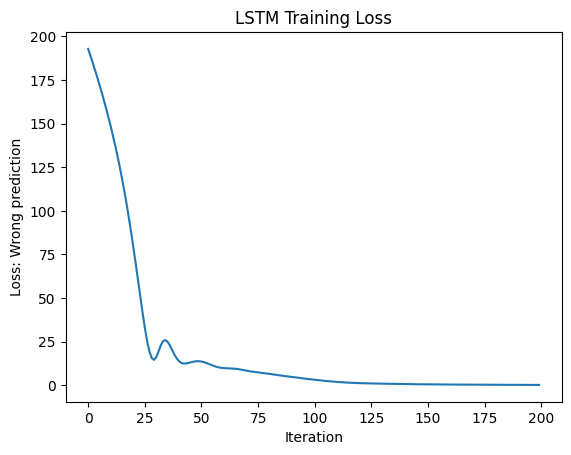

In [ ]:
plt.plot(history.history['loss'])
plt.xlabel("Iteration")
plt.ylabel("Loss: Wrong prediction")
plt.title("LSTM Training Loss")
plt.show()

In [ ]:
test_sequence = np.array([16,17,18,19,20])
test_sequence = test_sequence.reshape(1, 5, 1)

prediction = model.predict(test_sequence)

print("Input:", test_sequence)
print("Predicted next value:",prediction[0][0] )

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
Input: [[[16]
  [17]
  [18]
  [19]
  [20]]]
Predicted next value: 21.08619


#Using sentences in LSTM

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

In [ ]:
text = """
I love machine learning
I love deep learning
I love natural language processing
machine learning is interesting
deep learning is powerful
natural language processing is useful
machine learning uses data
deep learning uses neural networks
natural language processing uses text
"""

In [ ]:
# Convert text into sentences
sentences = text.lower().strip().split("\n")
print(sentences)

['i love machine learning', 'i love deep learning', 'i love natural language processing', 'machine learning is interesting', 'deep learning is powerful', 'natural language processing is useful', 'machine learning uses data', 'deep learning uses neural networks', 'natural language processing uses text']


In [ ]:
tokenizer = Tokenizer()
tokenizer.fit_on_texts(sentences)

total_words = len(tokenizer.word_index) + 1
print(total_words)
print("Vocabulary:")
print(tokenizer.word_index)

18
Vocabulary:
{'learning': 1, 'i': 2, 'love': 3, 'machine': 4, 'deep': 5, 'natural': 6, 'language': 7, 'processing': 8, 'is': 9, 'uses': 10, 'interesting': 11, 'powerful': 12, 'useful': 13, 'data': 14, 'neural': 15, 'networks': 16, 'text': 17}


In [ ]:
input_sequences = []

for sentence in sentences:
    token_list = tokenizer.texts_to_sequences([sentence])[0]

    for i in range(1, len(token_list)):
        sequence = token_list[:i + 1]
        input_sequences.append(sequence)

# Find maximum sequence length
max_sequence_len = max(len(seq) for seq in input_sequences)

# Pad sequences
input_sequences = pad_sequences(
    input_sequences,
    maxlen=max_sequence_len,
    padding='pre'
)

In [ ]:
print(tokenizer.word_index)

{'learning': 1, 'i': 2, 'love': 3, 'machine': 4, 'deep': 5, 'natural': 6, 'language': 7, 'processing': 8, 'is': 9, 'uses': 10, 'interesting': 11, 'powerful': 12, 'useful': 13, 'data': 14, 'neural': 15, 'networks': 16, 'text': 17}


In [ ]:
X = input_sequences[:, :-1]
y = input_sequences[:, -1]
print(X)
print(y)

[[ 0  0  0  2]
 [ 0  0  2  3]
 [ 0  2  3  4]
 [ 0  0  0  2]
 [ 0  0  2  3]
 [ 0  2  3  5]
 [ 0  0  0  2]
 [ 0  0  2  3]
 [ 0  2  3  6]
 [ 2  3  6  7]
 [ 0  0  0  4]
 [ 0  0  4  1]
 [ 0  4  1  9]
 [ 0  0  0  5]
 [ 0  0  5  1]
 [ 0  5  1  9]
 [ 0  0  0  6]
 [ 0  0  6  7]
 [ 0  6  7  8]
 [ 6  7  8  9]
 [ 0  0  0  4]
 [ 0  0  4  1]
 [ 0  4  1 10]
 [ 0  0  0  5]
 [ 0  0  5  1]
 [ 0  5  1 10]
 [ 5  1 10 15]
 [ 0  0  0  6]
 [ 0  0  6  7]
 [ 0  6  7  8]
 [ 6  7  8 10]]
[ 3  4  1  3  5  1  3  6  7  8  1  9 11  1  9 12  7  8  9 13  1 10 14  1
 10 15 16  7  8 10 17]


In [ ]:
model = Sequential([
    Embedding(
        input_dim=total_words,
        output_dim=32,
        input_length=max_sequence_len - 1
    ),
    LSTM(64),
    Dense(total_words, activation='softmax')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [ ]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
model.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_6 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.fit(X,y, epochs=300, verbose=1)

Epoch 1/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.0000e+00 - loss: 2.8917
Epoch 2/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.0645 - loss: 2.8877
Epoch 3/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.0968 - loss: 2.8836
Epoch 4/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.0968 - loss: 2.8795
Epoch 5/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.1613 - loss: 2.8754
Epoch 6/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 0.1290 - loss: 2.8711
Epoch 7/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 0.1935 - loss: 2.8666
Epoch 8/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 0.1935 - loss: 2.8619
Epoch 9/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.1935 - loss: 2.8570
Epoch 10/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.1935 - loss: 2.8517
Epoch 11/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 0.1935 - loss: 2.8461
Epoch 12/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.1935 - 

In [ ]:
def predict_next_word(seed_text):

    token_list = tokenizer.texts_to_sequences([seed_text.lower()])[0]

    token_list = pad_sequences(
        [token_list],
        maxlen=max_sequence_len - 1,
        padding='pre'
    )

    prediction = model.predict(token_list, verbose=1)

    predicted_word_id = np.argmax(prediction, axis=1)[0]

    for word, index in tokenizer.word_index.items():
        if index == predicted_word_id:
            return word

    return None

In [ ]:
test_sentences = ["Deep learning can ",
                  "Machine learning is",
                  "Natural language processing"]

for sentence in test_sentences:
    next_word = predict_next_word(sentence)
    print(f"{sentence} -> {next_word}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
Deep learning can  -> is
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
Machine learning is -> interesting
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
Natural language processing -> is


In [ ]:
#Gradio- For UI
!pip install -q gradio

In [ ]:
import gradio as gr

def predict_next_word_ui(seed_text):

    if not seed_text.strip():
        return "Please enter some text."

    token_list = tokenizer.texts_to_sequences(
        [seed_text.lower()]
    )[0]

    if len(token_list) == 0:
        return "Words not found in the training vocabulary."

    token_list = pad_sequences(
        [token_list],
        maxlen=max_sequence_len - 1,
        padding='pre'
    )

    prediction = model.predict(
        token_list,
        verbose=0
    )

    predicted_word_id = np.argmax(
        prediction,
        axis=1
    )[0]

    for word, index in tokenizer.word_index.items():

        if index == predicted_word_id:
            return word

    return "Unable to predict."

In [ ]:
def add(a,b):
  return a+b



In [ ]:
import gradio as gr

demo=gr.Interface(fn=add, inputs=[
    gr.Number(label="Enter your first number"),
    gr.Number(label="Enter your second number")],
    outputs=gr.Number(label="Result: Add"), title="Addition calculator",
    description="Enter two numbers and let the machine do the rest..." )

demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://1704c1f503bae7c710.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
interface = gr.Interface(
    fn=predict_next_word_ui,

    inputs=gr.Textbox(
        label="Enter a sentence",
        placeholder="Example: machine learning uses"
    ),

    outputs=gr.Textbox(
        label="Predicted Next Word"
    ),

    title="LSTM Next Word Predictor",

    description="""
    Enter a sentence and the LSTM model will predict
    the next word based on the training data.
    """
)

# Launch
interface.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://6e3435aeddbb9ac912.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
